# 03 · Классификация и калибровка вероятностей

Сравниваем логистическую регрессию и SVM на Wisconsin Diagnostic Breast Cancer. Положительный класс: **malignant = 1**. Порог для классификации фиксирован на 0.5.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'mlproject').is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError('Open this notebook inside the project folder')
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display, Image
from mlproject.data import dataset, split
from mlproject.experiments import run


In [2]:
X,y=dataset('classification')
display(pd.Series(y).value_counts().rename_axis('malignant').to_frame('count'))
print('Объекты и признаки:',X.shape)

,count
malignant,
0,357
1,212


Объекты и признаки: (569, 30)


## Протокол

C выбирается из 0.1, 1, 10 по validation ROC-AUC. Для SVM выполняется sigmoid-калибровка на трёх внутренних train-folds. Масштабирование находится внутри модели каждого fold. Validation и test в обучение калибратора не попадают.

In [3]:
results=run('03')
display(results.round(4))

,model,accuracy,precision,recall,f1,roc_auc,brier,log_loss,C,val_roc_auc
0,Dummy prior,0.6316,0.0000,0.0000,0.0000,0.5000,0.2327,0.6581,NaN,NaN
1,Logistic regression,0.9737,0.9756,0.9524,0.9639,0.9954,0.0214,0.0789,1.0,0.9957
2,Calibrated SVM,0.9737,0.9756,0.9524,0.9639,0.9944,0.0251,0.1062,1.0,0.9961


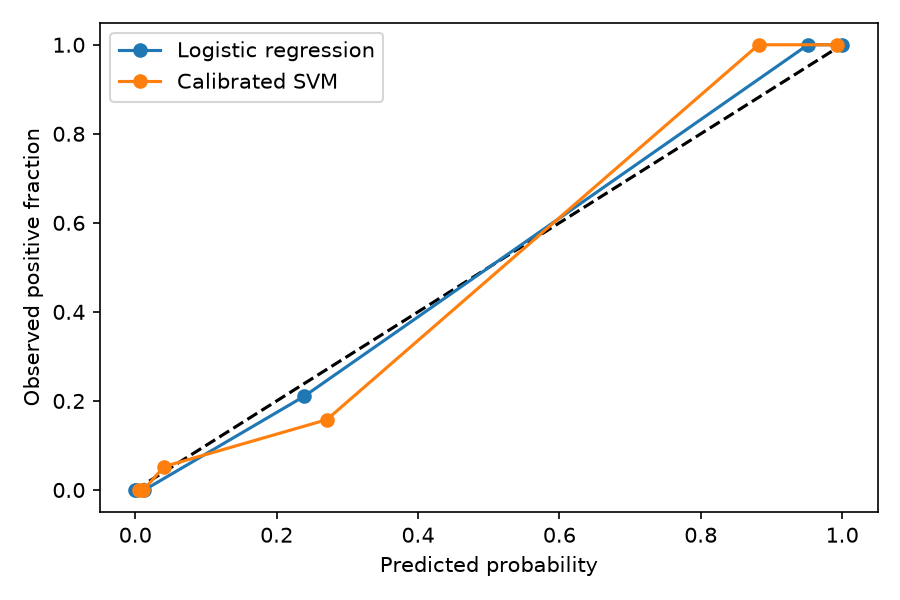

lr confusion matrix: строки — истинный класс, столбцы — прогноз


,0,1
0,71,1
1,2,40


svm confusion matrix: строки — истинный класс, столбцы — прогноз


,0,1
0,71,1
1,2,40


In [4]:
display(Image(filename=str(ROOT/'reports/03_calibration.png')))
for name in ['lr','svm']:
    print(name, 'confusion matrix: строки — истинный класс, столбцы — прогноз')
    display(pd.read_csv(ROOT/f'reports/03_confusion_{name}.csv',header=None))

In [5]:
best=results.dropna(subset=['val_roc_auc']).sort_values('val_roc_auc',ascending=False).iloc[0]
print(f'Выбрана по validation: {best.model}. Test ROC-AUC={best.roc_auc:.4f}; recall={best.recall:.4f}; Brier={best.brier:.4f}.')

Выбрана по validation: Calibrated SVM. Test ROC-AUC=0.9944; recall=0.9524; Brier=0.0251.


## Выводы

ROC-AUC измеряет ранжирование, Brier/log loss — качество вероятностей. На малом test калибровочная кривая нестабильна; по ней не выбираем метод повторно. Оценка не является медицинской валидацией.